<a href="https://colab.research.google.com/github/tatianacastanedaa/ladb_mobility_economy_project_student/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
print("plans", plans.info)

plans <bound method DataFrame.info of   plan_name  messages_included  gb_per_month  minutes_included  \
0    Basico                100             5               100   
1   Premium                500            20               600   

   usd_monthly_pay  usd_per_gb  usd_per_message  usd_per_minute  
0               12         1.2             0.08            0.10  
1               25         1.0             0.05            0.07  >


In [ ]:
print("users", users.info)

users <bound method DataFrame.info of       user_id first_name last_name  age      city  \
0       10000     Carlos    Garcia   38  Medellín   
1       10001      Mateo    Torres   53         ?   
2       10002      Sofia   Ramirez   57      CDMX   
3       10003      Mateo   Ramirez   69    Bogotá   
4       10004      Mateo    Torres   63       GDL   
...       ...        ...       ...  ...       ...   
3995    13995        Ana     Lopez   60  Medellín   
3996    13996     Carlos   Ramirez   24  Medellín   
3997    13997        Ana     Lopez   58    Bogotá   
3998    13998    Mariana     Lopez   57    Bogotá   
3999    13999        Ana     Lopez   20    Bogotá   

                           reg_date     plan churn_date  
0     2022-01-01 00:00:00.000000000   Basico        NaN  
1     2022-01-01 06:34:17.914478619   Basico        NaN  
2     2022-01-01 13:08:35.828957239   Basico        NaN  
3     2022-01-01 19:42:53.743435858  Premium        NaN  
4     2022-01-02 02:17:11.657914478

In [ ]:
print("usage", usage.info)

usage <bound method DataFrame.info of           id  user_id  type                           date  duration  length
0          1    10332  call  2024-01-01 00:00:00.000000000      0.09     NaN
1          2    11458  text  2024-01-01 00:06:30.969774244       NaN    39.0
2          3    11777  text  2024-01-01 00:13:01.939548488       NaN    36.0
3          4    10682  call  2024-01-01 00:19:32.909322733      1.53     NaN
4          5    12742  call  2024-01-01 00:26:03.879096977      4.84     NaN
...      ...      ...   ...                            ...       ...     ...
39995  39996    13497  call  2024-06-29 23:33:56.120903022      5.75     NaN
39996  39997    10941  call  2024-06-29 23:40:27.090677266      3.06     NaN
39997  39998    13038  call  2024-06-29 23:46:58.060451510      8.74     NaN
39998  39999    10863  text  2024-06-29 23:53:29.030225754       NaN    43.0
39999  40000    10759  call  2024-06-30 00:00:00.000000000      1.32     NaN

[40000 rows x 6 columns]>


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print("users conteo valores nulos:", users.isna().sum())
print("users proporcion de nulos por columna:", users.isna().mean())

users conteo valores nulos: user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
users proporcion de nulos por columna: user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print("usage conteo valores nulos:", usage.isna().sum())
print("usage proporcion de nulos por columna:", usage.isna().mean())

usage conteo valores nulos: id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
usage proporcion de nulos por columna: id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---


**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
- Indica qué harías: ¿imputar, eliminar, ignorar?
  
- La columa city del dataset USERS tiene 469 nulos y una proporción de 11.67%, teniendo en cuenta el porcentaje de nulos, se recomienda investigar la causa y evaluar imputación o decidir conservarlos como desconocidos

- La columna churn_date del dataset USER tiene 3534 nulos y una proporción de 88.35%, teniendo en cuenta la naturaleza de la columna es probable que los usuarios no hayan cancelado el servicio, la recomendación es no imputar estos valores, podrian dejarse como nulos
  
- La columna date del dataset date tiene 50 nulos y una proporción de 0.125%, estos valores se pueden eliminar, pues será complicado recuperar las fechas

- La columna duration del dataset USAGE tiene 22076 nulos y una proporción de 55.19%, tiene una proporción alta, se recomienda investigar y determinar cuál será su tratamiento
  
- La columna length del dataset USAGE tiene 17896 nulos y una proporción de 44.74%, al tener una proporción tan alta, se considera primero hacer una revisión además de su relación con type, luego se evalua su tratamiento




### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:

numeric_columns_users = ['user_id', 'age']
users[numeric_columns_users].describe()


,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no representa valores sospechosos, los identificadores están dentro del rango esperado
- La columna `age` vemos un mínimo de -999 y un promedio de 33.74 años

In [ ]:

numeric_columns_usage = ['id', 'user_id']
usage[numeric_columns_usage].describe()


,id,user_id
count,40000.00000,40000.000000
mean,20000.50000,12002.405975
std,11547.14972,1157.279564
min,1.00000,10000.000000
25%,10000.75000,10996.000000
50%,20000.50000,12013.000000
75%,30000.25000,13005.000000
max,40000.00000,13999.000000



- Las columnas `id` presenta los valores esperados para la naturaleza de la columna
- Las columnas `user_id` presenta los valores esperados para la naturaleza de la columna


In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595



- La columna `city` es consistente con los nulos que ya se habían identificado, no se evidencia un sentinel categórico
- La columna `plan` no se observan valores sospechosos ni sentinels


In [ ]:

# explorar columna categórica de usage
usage['type'].describe()


count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` no se observan valores sosprechosos ni sentinels


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

- Al revisar la columna city del dataset USERS se evidencian 7 categorias, no se encontraton valores inválidos o sentinels, al igual que en la columna de plan, que tiene 2 categrías.
- En el dataset de USAGE en la columna type que tiene 2 categorías no se observan valores sospechosos o sentinels.
- En ninguno de los tres casos es necesario hacer algún tipo de corrección.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])


In [ ]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


In [ ]:
users['reg_date'].dt.year

0       2022
1       2022
2       2022
3       2022
4       2022
        ... 
3995    2024
3996    2024
3997    2024
3998    2024
3999    2024
Name: reg_date, Length: 4000, dtype: int64

En `reg_date`, se ha modificado la columna 'reg_date' a tipo de dato de fecha

In [ ]:
usage['date'].dt.year

0        2024.0
1        2024.0
2        2024.0
3        2024.0
4        2024.0
          ...  
39995    2024.0
39996    2024.0
39997    2024.0
39998    2024.0
39999    2024.0
Name: date, Length: 40000, dtype: float64

In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


En `date`, se hizo la modificación del tipo a fecha  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  

- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
- En el dataset de USERS en la columna de 'reg_date' no se observan años imposibles, sino esperados. Sin embargo en la columna 'date' del dataset USAGE los años tienen un decimal .0, pero podemos ver que la columna es tipo float64, es posible que en esta columna encontremos valores nulos o NaN


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:

# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
(users['age']==-999).sum()

0

In [ ]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].isna().sum()


565

In [ ]:
users['reg_date'].dtype

dtype('<M8[ns]')

In [ ]:
# Marcar fechas futuras como NA para reg_date
users['reg_date'] = users['reg_date'].where(users['reg_date'] <= pd.Timestamp('2024-12-31'), pd.NaT)

# Verificar cambios
users['reg_date'].isna().sum()

40

In [ ]:
users['reg_date'].dtype

dtype('<M8[ns]')

In [ ]:
users['reg_date'].dropna().max()

Timestamp('2024-12-31 00:00:00')

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Según los resultados obtenidos para ambas columnas, se tiene una fuerte relación con type y los valores faltantes. Los nulos podrían ser estructurales, ya que duration corresponde a la duración de las llamadas y length corresponde a la longitud de los mensajes de texto.
Teniendo en cuenta lo anterior, se recomienda conservarlos como nulos ya que representa información que no aplica al tipo de registro correspondiente

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)



,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on = 'user_id', how= 'inner')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_numericas].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000
mean,48.124531,5.524381,4.478120,23.317054
std,17.692032,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True).mul(100).round(2)

Basico     64.87
Premium    35.13
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

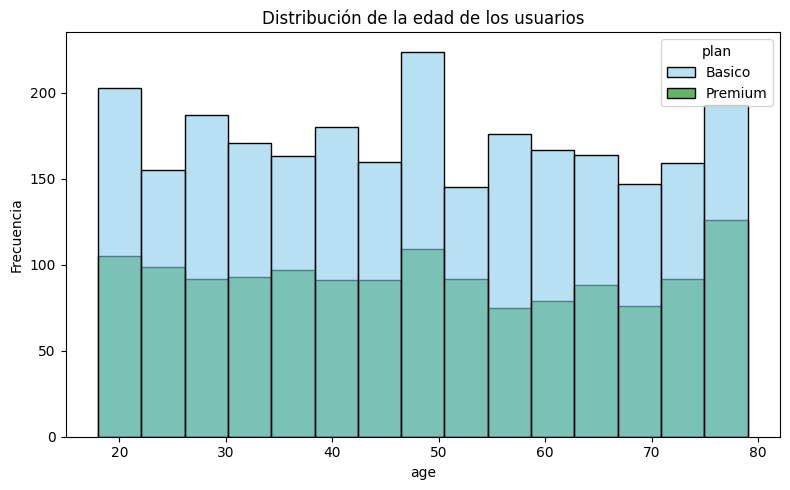

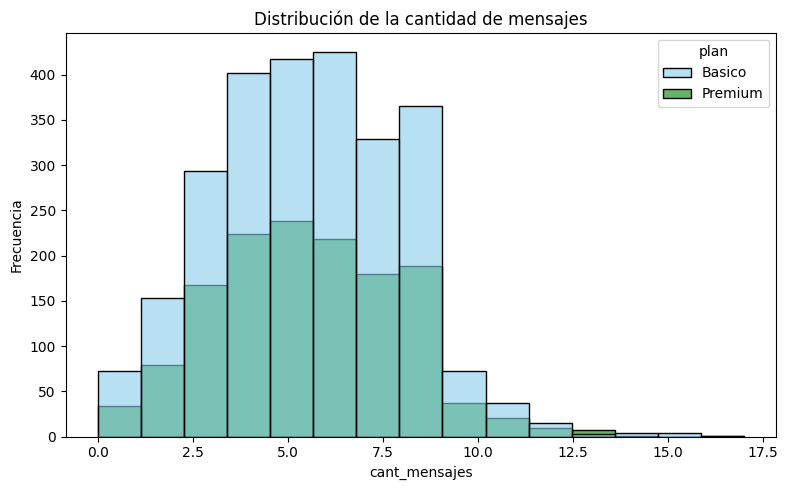

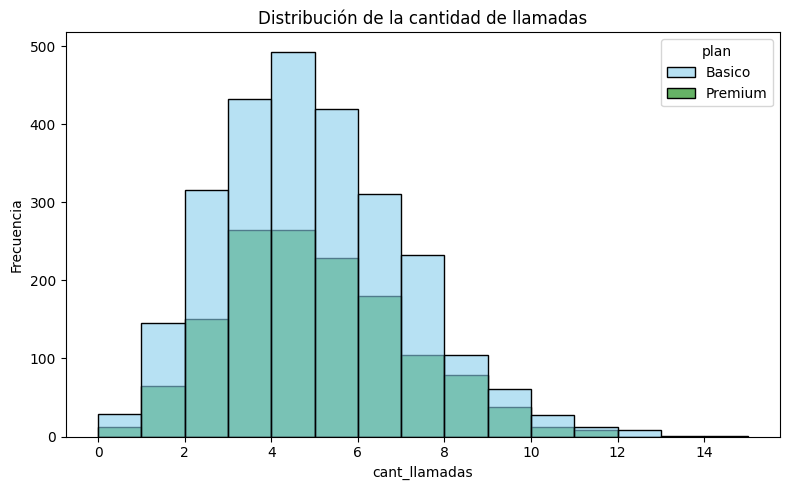

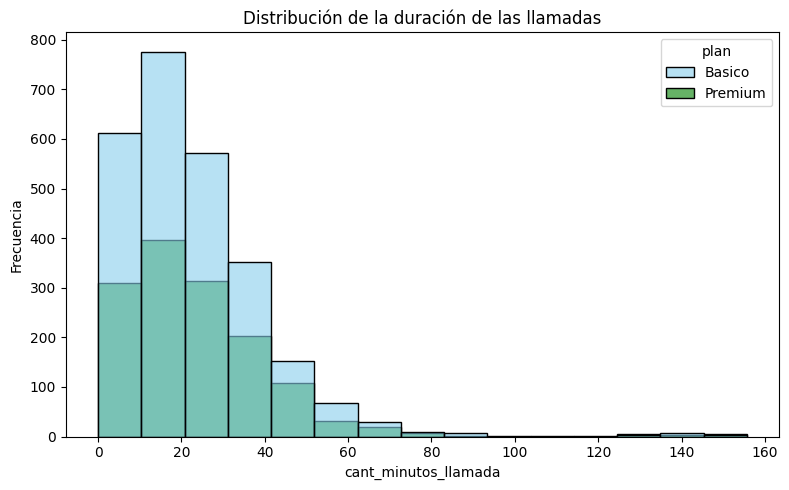

In [ ]:
# Histograma para visualizar la edad (age)

columnas = {
    "age": "Distribución de la edad de los usuarios",
    "cant_mensajes": "Distribución de la cantidad de mensajes",
    "cant_llamadas": "Distribución de la cantidad de llamadas",
    "cant_minutos_llamada": "Distribución de la duración de las llamadas"
}

for columna, titulo in columnas.items():
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=user_profile,
        x=columna,
        hue="plan",
        palette=["skyblue", "green"],
        bins=15,
        alpha=0.6
    )

    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

💡Insights Distribución de la Edad de los Usuario:
- Las edades de los usuarios presentan un comportamiento relativamente uniforme en la distribución, no se observa una concentración dominante en algún rango de edad. El plan básico tiene frecuencias más altas, podria deberse a tener una mayor cantidad de usuarios y visiblemente no se observa una diferencia que marque una gran diferencia entre la distribución de las edades entre los planes.

💡Insights Distribución de la Cantidad de mensajes:
- Observamos un sesgo a la derecha, teniendo en cuenta que la mayoría de los usuarios se encuentran concentrados en cantidades moderadas de mensajes, es decir entre 3 y 8 mensajes. El patrón general es similar entre los usuarios de ambos planes, aunque de nuevo la frecuencia del plan básico es mayor.

💡Insights Distribución de la Cantidad de Llamadas:
- Observamos un ligero sesgo a la derecha, con una mayor concentración de usuarios que realizaron entre 3 a 6 llamadas. Los usuarios de ambos planes se han comportado de manera similar, se puede observar que el máximo de frecuencia en las llamadas es de 4 a 5. Se tienen pocos usuarios con cantidades elevadas de llamadas en comparación a la mayoría.

💡Insights Distribución de la Duración de Llamadas:
- La distrubución de la duración de llamadas presenta un sesgo marcado a la derecha. Un grupo bajo de usuarios presenta una duración larga en las llamadas, mientras que la mayoría de usuarios presenta duración baja o moderada en sus llamadas; este comportamiento se observa en ambos planes. Los valores atípicos deberán observase a detalle, para determinar si son outliers o comportamientos legítimos de los usuarios.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna
.

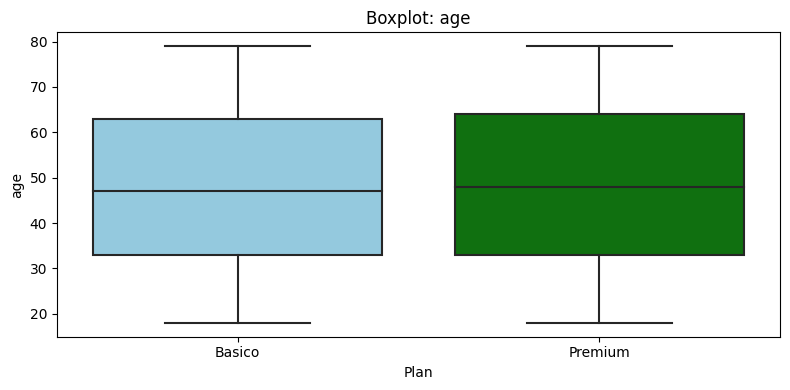

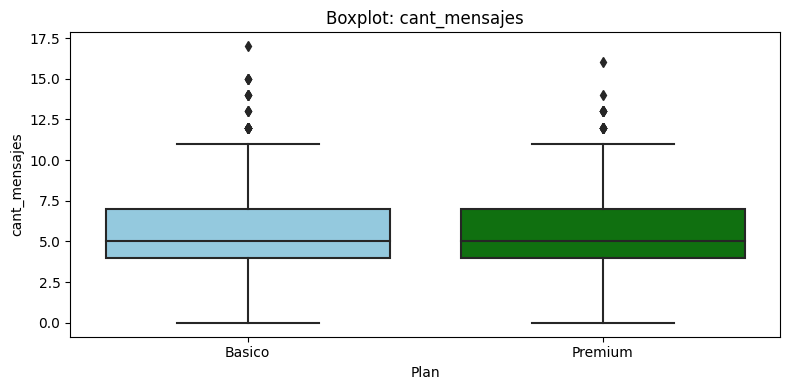

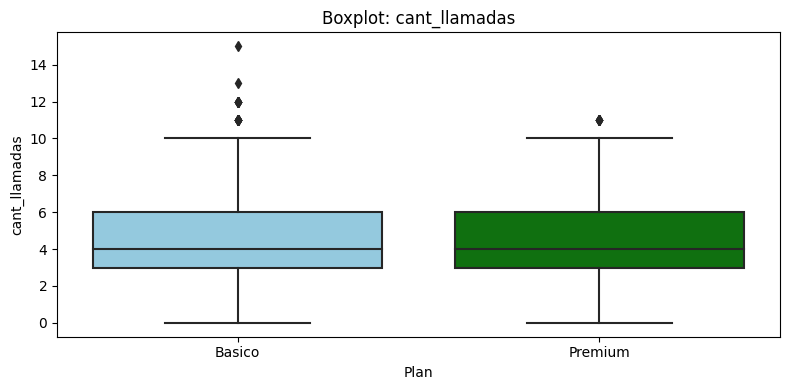

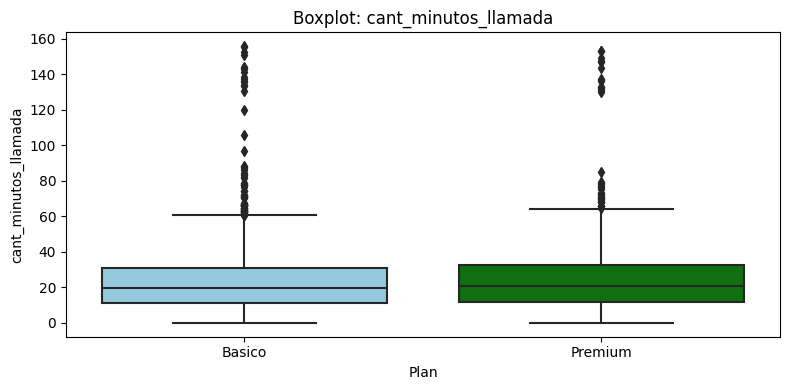

In [ ]:
# Visualizando usando BoxPlot

columnas_numericas = [
    "age",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

for col in columnas:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=user_profile,
        x="plan",
        y=col,
        palette=["skyblue", "green"]
    )

    plt.title(f"Boxplot: {col}")
    plt.xlabel("Plan")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()


💡Insights:
- Age: no presenta ningún valor atípico o outliers en ninguno de los dos tipos de planes. Se puede observar que la distribución de las edades son bastantes similares
  
- cant_mensajes: Se evidencian valores atípicos superiores en ambos planes, con usuarios que reportan más de 11 mensajes. El plan Básico presenta valores extremos de hasta 17 mensajes, mientras que Premium alcanza 16. Sin embargo, las cajas y las medianas son similares, lo que sugiere que el comportamiento habitual de envío de mensajes es comparable entre ambos planes.

- cant_llamadas: En los dos planes se observan valores atípicos superiores. En Básico aparecen usuarios con hasta 15 llamadas, mientras que en Premium el máximo es de 11. A pesar de estas diferencias en los extremos, la mediana es de aproximadamente 4 llamadas en ambos planes, por lo que el uso habitual de llamadas es similar.

- cant_minutos_llamada: Aqui vemos una mayor cantidad y dispersión de valores atípicos superiores. En ambos planes hay usuarios que superan ampliamente los límites habituales de consumo, con máximos cercanos a 156 minutos en Básico y 153 minutos en Premium. Las medianas son relativamente similares, alrededor de 20 minutos, lo que indica que estos consumos elevados corresponden a un grupo reducido de usuarios y no al comportamiento típico de la mayoría


In [ ]:

# Separar el DataFrame por tipo de plan
basico = user_profile[user_profile["plan"] == "Basico"].copy()
premium = user_profile[user_profile["plan"] == "Premium"].copy()

# Verificar que los grupos se hayan creado correctamente
print("Usuarios en el plan Básico:", len(basico))
print("Usuarios en el plan Premium:", len(premium))

Usuarios en el plan Básico: 2594
Usuarios en el plan Premium: 1405


In [ ]:
# Calcular límites con el método IQR

resultados_iqr = []

for nombre_plan, perfil in {
    "Basico": basico,
    "Premium": premium
}.items():

    for col in columnas_numericas:
        datos = perfil[col].dropna()

        Q1 = datos.quantile(0.25)
        Q3 = datos.quantile(0.75)
        IQR = Q3 - Q1

        limite_inferior = Q1 - 1.5 * IQR
        limite_superior = Q3 + 1.5 * IQR

        outliers_inferiores = datos[datos < limite_inferior]
        outliers_superiores = datos[datos > limite_superior]

        resultados_iqr.append({
            "plan": nombre_plan,
            "variable": col,
            "Q1": Q1,
            "Q3": Q3,
            "IQR": IQR,
            "limite_inferior": limite_inferior,
            "limite_superior": limite_superior,
            "outliers_inferiores": len(outliers_inferiores),
            "outliers_superiores": len(outliers_superiores)
        })

tabla_iqr = pd.DataFrame(resultados_iqr)

tabla_iqr.round(2)


,plan,variable,Q1,Q3,IQR,limite_inferior,limite_superior,outliers_inferiores,outliers_superiores
0,Basico,age,33.00,63.00,30.00,-12.00,108.00,0,0
1,Basico,cant_mensajes,4.00,7.00,3.00,-0.50,11.50,0,27
2,Basico,cant_llamadas,3.00,6.00,3.00,-1.50,10.50,0,22
3,Basico,cant_minutos_llamada,10.91,30.80,19.89,-18.92,60.64,0,73
4,Premium,age,33.00,64.00,31.00,-13.50,110.50,0,0
5,Premium,cant_mensajes,4.00,7.00,3.00,-0.50,11.50,0,19
6,Premium,cant_llamadas,3.00,6.00,3.00,-1.50,10.50,0,8
7,Premium,cant_minutos_llamada,11.59,32.52,20.93,-19.80,63.91,0,37


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no

resultados_maximos = []

for nombre_plan, perfil in {
    "Basico": basico,
    "Premium": premium
}.items():

    for col in columnas_numericas:
        datos = perfil[col].dropna()

        limite_superior = tabla_iqr.loc[
            (tabla_iqr["plan"] == nombre_plan) &
            (tabla_iqr["variable"] == col),
            "limite_superior"
        ].iloc[0]

        maximo = datos.max()

        resultados_maximos.append({
            "plan": nombre_plan,
            "variable": col,
            "limite_superior": limite_superior,
            "maximo": maximo,
            "max_supera_limite": maximo > limite_superior
        })

tabla_maximos = pd.DataFrame(resultados_maximos)

tabla_maximos.round(2)


,plan,variable,limite_superior,maximo,max_supera_limite
0,Basico,age,108.00,79.00,False
1,Basico,cant_mensajes,11.50,17.00,True
2,Basico,cant_llamadas,10.50,15.00,True
3,Basico,cant_minutos_llamada,60.64,155.69,True
4,Premium,age,110.50,79.00,False
5,Premium,cant_mensajes,11.50,16.00,True
6,Premium,cant_llamadas,10.50,11.00,True
7,Premium,cant_minutos_llamada,63.91,153.06,True


💡Insights:
- cant_mensajes: Se identificaron valores atípicos superiores en ambos planes, sus valores máximos superan el límite superior establecido mediante el método IQR. Se ha decidido conservar estos valores atípicos, pues no se tiene evidencia de que correspondan a errores; podrían representar clientes que hacen un uso elevado de los mensajes de texto. Estos usuarios podrían ser de gran valor para ofertas comerciales
  
- cant_llamadas: Luego de hacer los cálculos mediante el método IQR se evidencian valores atípicos superiores en ambos planes, pues los máximos superan los límites superiores. Se recomienda conservar estos registros, puesto que no se ha identificado evidencia de errores en los datos y los valores podrían corresponder a clientes que realizan una mayor cantidad de llamadas. Se podrían aprovechar estos clientes que hacen una mayor cantidad de llamadas, podría ser un segmento interesante para una propuesta comercial

- cant_minutos_llamada: Se han identificado valores atípicos superiores en ambos planes, con máximos considerablemente superiores a los límites establecidos luego de aplicar el método IQRSe decide conservar los valores atípico, pues su permanencia permite incluir a los clientes con un consumo elevado de minutos, quienes podrían constituir un segmento de interés comercial para la empresa.

---


## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos


In [ ]:
# Crear columna grupo_uso

def seg_clientes_uso(row):

    if row["cant_llamadas"] < 5 and row["cant_mensajes"] < 5:
        return "Bajo uso"

    elif row["cant_llamadas"] < 10 and row["cant_mensajes"] < 10:
        return "Uso medio"

    else:
        return "Alto uso"


# 2. Aplicar la función a cada fila del DataFrame
user_profile["grupo_uso"] = user_profile.apply(
    seg_clientes_uso,
    axis=1
)

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def seg_clientes_edad(row):

    if row["age"] < 30:
        return "Jove"

    elif row["age"] < 60:
        return "Adulto"

    else:
        return "Adulto Mayor"


# 2. Aplicar la función a cada fila del DataFrame
user_profile["grupo_edad"] = user_profile.apply(
    seg_clientes_edad,
    axis=1
)


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.


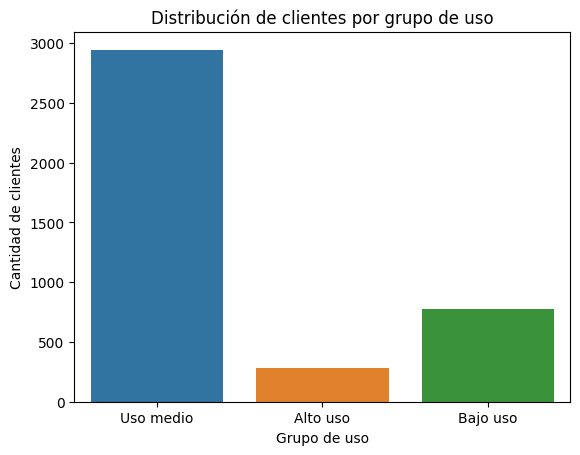

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x="grupo_uso")

plt.title("Distribución de clientes por grupo de uso")
plt.xlabel("Grupo de uso")
plt.ylabel("Cantidad de clientes")

plt.show()


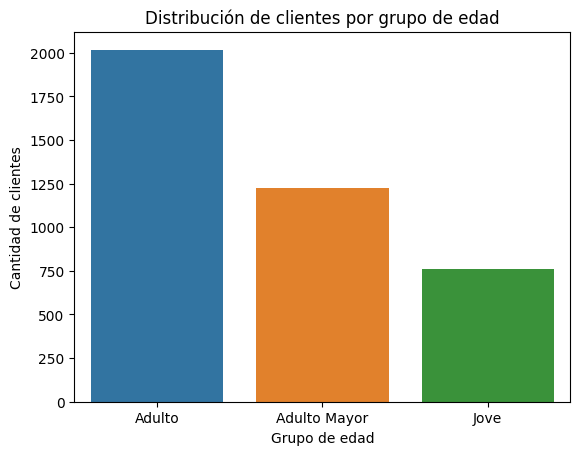

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")

plt.title("Distribución de clientes por grupo de edad")
plt.xlabel("Grupo de edad")
plt.ylabel("Cantidad de clientes")

plt.show()


---


## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**

- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

Los problemas que se encontraron originalmente en el dataset fueron:  
* Ciudad (users): del total de 4.000 usuarios se tienen 469 valores nulos (11,73 %). Al reemplazar los signos ? por valores nulos, el total aumentó a 565 registros (14,13 %).

* Fecha de cancelación (churn_date):Se conservaron los 3.534 valores nulos (88,35 %), pues podrían indicar que el usuario no había cancelado el servicio.

* Fecha de uso (usage.date): 50 valores nulos de 40.000 registros (0,125 %). Se decidió evaluar su eliminación por la dificultad de recuperar esas fechas.

* Duración (usage.duration): Se identificó que 22.076 valores nulos (55,19 %), corresponden principalmente a registros de mensajes de texto.

* Longitud (usage.length): Se encontraron 17.896 valores nulos (44,74 %), estos valores corresponden principalmente a llamadas, donde la longitud del mensaje no aplica.

* Edad (users.age): durante la exploración se identificó el valor sospechoso -999, que no corresponde a una edad válida. No Se hizo el calculo con el número original de registros afectados, por lo que no es posible calcular su porcentaje.

* Ciudad (users.city): también se detectó el símbolo ? como un valor que debía tratarse como faltante.

* Fecha de registro (users.reg_date): se identificaron 40 fechas posteriores al 31 de diciembre de 2024, que debían revisarse por estar fuera del periodo de análisis.

Según el nivel de uso se pudo identificar tres grupos de clientes: uso medio, bajo uso y alto uso. En orden de mayor a menor cantidad de clientes, tenemos, el de uso medio, con aproximadamente 2.950 clientes, seguido por el de bajo uso, con cerca de 780 y el grupo de alto uso es el más pequeño, con aproximadamente 290 clientes.

El en segmento de edad se identificaron tres grupos por edad: jóvenes, adultos y adultos mayores. El grupo más numeroso es el de los adultos, con cerca de 2.020 clientes, seguidos por los adultos mayores, con aproximadamente 1.230 y por último los jóvenes representan el grupo más pequeño, con alrededor de 760 clientes.

En concordancia con los resultados los segmentos más valiosos son los que concentran más clientes, los de alto uso y los de uso medio. Son los clientes que ConnectaTel debe priorizar la fidelización e identificar oportunidades para incrementar el consumo de los clientes de bajo uso.

En ambos planes que la empresa tiene diponible se identificaron valores atípicos superiores, para las variables cantidad de mensajes, cantidad de llamadas y minutos de llamada. Desde la perspectiva del negocio, estos patrones representan una oportunidad para ConnectaTel. Los clientes que envían más mensajes, realizan más llamadas o consumen una mayor cantidad de minutos podrían ser candidatos para ofertas comerciales personalizadas, planes con mayores beneficios o paquetes que se ajusten mejor a sus necesidades de consumo. Además, identificarlos permitiría evaluar estrategias de fidelización dirigidas a clientes que podrían tener un alto valor para la compañía.

Se recomienda a ConnectaTel mejorar su oferta mediante planes diferenciados por nivel y tipo de consumo, con alternativas accesibles para usuarios de bajo uso, beneficios para el grupo de uso medio y opciones de mayor capacidad para clientes de alto consumo. Los clientes con mayores niveles de uso tanto en mensajes como en llamadas, podrían representar una oportunidad de un plan que se ajuste a sus necesidades, tal vez la fidelización podría ser un factor clave en este caso.
El segmento más numeroso es el de uso medio, se recomienda evaluar la posibilidad de crear un plan intermedio, que se ajuste a las necesidades de este segmento, con paquetes combinados o incentivos para aumentar el consumo.
No se debe dejar de lado a los clientes de bajo uso, planes de baso presupuesto que permita que los clientes tenga acceso a un poco de los dos servicios (mensajes y llamadas)


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Durante la inspección incial y posterior limpieza de los datos, se detectaron valores nulos, así como valores inconsistentes en algunas de las variables, como edades negativas o fuera de los datos esperados. Estos problemas tuvieron un tratamiento que permitió solucionarlos adecuadamente.
- En las variables cantidad de llamadas, cantidad de mensajes y duración de las llamadas se detectaron valores atípicos en los dos planes disponibles. Se decidió que estos valores debían ser conservados, pues no hubo evidencia de que se debieran a un error, pues podrían representar clientes con alto uso de llamadas y mensajes, así como la duración de sus llamadas.


🔍 **Segmentos por Edad**
- Durante la revisión de los datos arrojados por la segmentación se encontraron tres grupos por edad: Jóvenes, Adultos y Adultos Mayores. Siendo el grupo de Adultos el que representa el mayor grupo
- El segundo grupo más grande es el de los adultos mayores, y el grupo más pequeño es el de los jóvenes; esto nos permite conocer la distribución por edad de los clientes.


📊 **Segmentos por Nivel de Uso**
- Se identificaron tres grupos de acuerdo al nivel de uso: Alto uso, Uso medio y Bajo uso. El segmento que tiene el mayor número de usuarios es el de uso medio, pues tiene aproximadamente 2.950 clientes.
- Los clientes del segmento de alto uso son los que se encuentran en el gropo más pequeño, podrían representar una gran oportunidad comercia, por su elevado uso de llamadas y mensajes.


➡️ Esto sugiere que ConnectaTel podría mejorar sus estrategias comerciales teniendo en cuenta la segmentación basada en las necesidades y los patrones de consumo de sus clientes. La edad y el nivel de uso se podrían cruzar y analizar los ingresos y la rentabilidad para determinar qué segmentos generan mayor valor para la empresa.


💡 **Recomendaciones**
- Considerar desarrollar planes de mayor capacidad o paquetes combinados para clientes de alto uso, y desarrollar estrategias de fidelización para conservar a estos clientes.

- No dejar de lado a los clientes de bajo uso, se podrían diseñar alternativas accesibles y beneficios adicionales para incentivar el consumo de los clientes de uso medio.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`